# Predicting metabolic disorder from health survey data

University machine learning project. The task was to prepare a patient dataset, explore it, look for
structure with unsupervised methods, train a classifier that separates patients with a metabolic
disorder from healthy individuals, and interpret the result.

Each group member worked on a different dataset. Mine was `patients_04.csv`: 5,129 patients,
17 features and the target column `dissease` (True / False).

**Contents**
1. Load the data
2. Exploratory analysis
3. Train / test split and missing data
4. Unsupervised analysis
5. Supervised models
6. Final model and evaluation
7. Feature importance and removing the best feature
8. Threshold and error analysis
9. Summary

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, silhouette_score)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

FIG_DIR = "../figures"
plt.rcParams["figure.dpi"] = 110

## 1. Load the data

In [2]:
df = pd.read_csv("../data/patients_04.csv")
print("Shape:", df.shape)
df.head()

Shape: (5129, 18)


,age,gender,bmi,high_chol,chol_check,history_stroke,history_heart_disease,history_smoking,amount_activity,alcohol_misuse,fruits,vegetables,health_gen,health_ment,health_phys,walking_diff,high_bp,dissease
0,50,female,40.0,NaN,NaN,False,True,True,notactive,2.0,NaN,False,5.0,0.0,21.0,True,high,True
1,63,female,35.0,normal,checked,True,True,False,notactive,NaN,True,False,5.0,0.0,14.0,True,high,True
2,57,male,36.0,high,checked,True,True,True,NaN,20.0,True,True,3.0,0.0,0.0,False,high,True
3,50,male,44.0,normal,checked,False,True,True,active,0.0,False,False,3.0,0.0,0.0,True,high,True
4,65,male,25.0,high,checked,False,False,True,active,1.0,True,True,2.0,0.0,0.0,False,high,True


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5129 entries, 0 to 5128
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    5129 non-null   int64  
 1   gender                 5129 non-null   str    
 2   bmi                    5129 non-null   float64
 3   high_chol              4842 non-null   str    
 4   chol_check             4849 non-null   str    
 5   history_stroke         5129 non-null   bool   
 6   history_heart_disease  5071 non-null   object 
 7   history_smoking        3587 non-null   object 
 8   amount_activity        4201 non-null   str    
 9   alcohol_misuse         4118 non-null   float64
 10  fruits                 5031 non-null   object 
 11  vegetables             5023 non-null   object 
 12  health_gen             5081 non-null   float64
 13  health_ment            5020 non-null   float64
 14  health_phys            4981 non-null   float64
 15  walking_diff   

## 2. Exploratory analysis

### 2.1 Feature types
Six features are numeric and eleven are categorical (all of them binary).

In [4]:
numeric_cols = ["age", "bmi", "alcohol_misuse", "health_gen", "health_ment", "health_phys"]

categorical_cols = ["gender", "amount_activity", "high_chol", "chol_check", "history_stroke",
                    "history_heart_disease", "history_smoking", "walking_diff", "high_bp",
                    "fruits", "vegetables"]

# some yes/no columns are stored as True/False with gaps, others as text.
# store every categorical column as text so they are all handled the same way.
for col in categorical_cols:
    df[col] = df[col].map(lambda v: v if pd.isna(v) else str(v)).astype(object)

df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,5129.0,NaN,NaN,NaN,62.25736,13.850116,15.0,53.0,63.0,72.0,108.0
gender,5129,2,male,3290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,5129.0,NaN,NaN,NaN,31.217391,7.612887,0.0,27.0,30.0,35.0,95.0
high_chol,4842,2,high,2917,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chol_check,4849,2,checked,4794,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history_stroke,5129,2,False,4693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history_heart_disease,5071,2,False,3957,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history_smoking,3587,2,True,1915,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_activity,4201,2,active,2800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alcohol_misuse,4118.0,NaN,NaN,NaN,2.383924,3.203184,0.0,0.0,2.0,3.0,27.0


### 2.2 Class distribution

dissease
True     4248
False     881
Name: count, dtype: int64
dissease
True     82.8
False    17.2
Name: proportion, dtype: float64


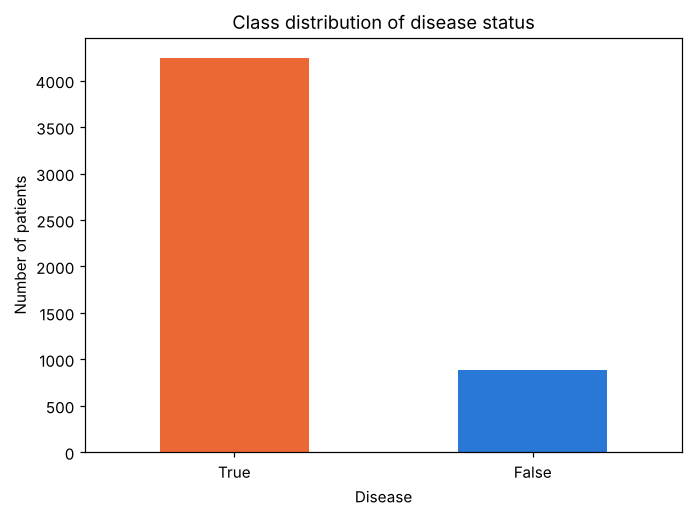

In [5]:
print(df["dissease"].value_counts())
print((df["dissease"].value_counts(normalize=True) * 100).round(1))

df["dissease"].value_counts().plot(kind="bar", color=["#eb6834", "#2a78d6"])
plt.title("Class distribution of disease status")
plt.xlabel("Disease")
plt.ylabel("Number of patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/class_distribution.png", dpi=150)
plt.show()

The classes are **imbalanced**: about 83% of patients have the disease and 17% are healthy.
This matters later. A model that calls everybody "diseased" already gets 83% accuracy, so accuracy
on its own is not a good measure here. I therefore also look at precision, recall, F1 and ROC-AUC.

### 2.3 Missing values

In [6]:
missing = pd.DataFrame({"missing": df.isna().sum(),
                        "percent": (df.isna().mean() * 100).round(1)}).sort_values("percent", ascending=False)
missing[missing["missing"] > 0]

,missing,percent
history_smoking,1542,30.1
alcohol_misuse,1011,19.7
amount_activity,928,18.1
high_chol,287,5.6
chol_check,280,5.5
health_phys,148,2.9
vegetables,106,2.1
health_ment,109,2.1
fruits,98,1.9
history_heart_disease,58,1.1


`history_smoking` (30%), `alcohol_misuse` (20%) and `amount_activity` (18%) have the most missing
values. Everything else is below 6%. No column is missing so much that it has to be dropped.

### 2.4 Numeric features and outliers

In [7]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,5129.0,62.257360,13.850116,15.0,53.0,63.0,72.0,108.0
bmi,5129.0,31.217391,7.612887,0.0,27.0,30.0,35.0,95.0
alcohol_misuse,4118.0,2.383924,3.203184,0.0,0.0,2.0,3.0,27.0
health_gen,5081.0,3.105097,1.085143,0.0,2.0,3.0,4.0,5.0
health_ment,5020.0,3.915737,8.472867,0.0,0.0,0.0,2.0,30.0
health_phys,4981.0,6.817105,12.446241,0.0,0.0,0.0,7.0,86.0


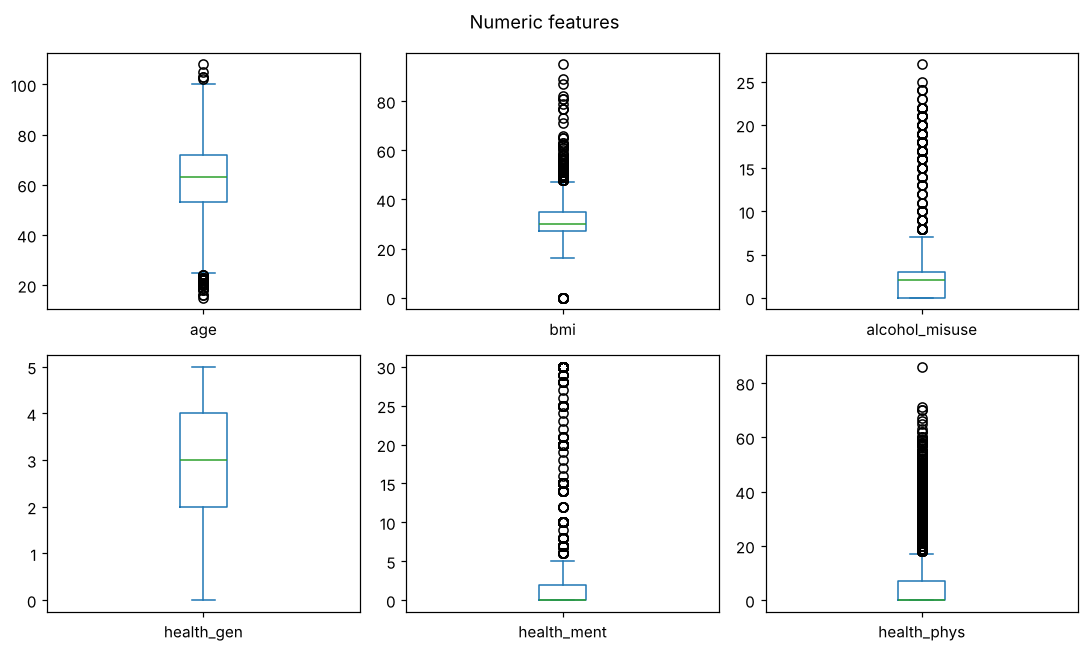

In [8]:
df[numeric_cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(10, 6))
plt.suptitle("Numeric features")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/numeric_boxplots.png", dpi=150)
plt.show()

In [9]:
# values that do not look physically possible
print("BMI of 0:                 ", (df["bmi"] == 0).sum())
print("health_phys above 30 days:", (df["health_phys"] > 30).sum())
print("Age above 100:            ", (df["age"] > 100).sum())
print("Age below 18:             ", (df["age"] < 18).sum())
print("health_gen of 0:          ", (df["health_gen"] == 0).sum())

BMI of 0:                  36
health_phys above 30 days: 385
Age above 100:             5
Age below 18:              3
health_gen of 0:           35


A few values are implausible: 36 patients have a BMI of 0, and `health_phys` is described as
"days in the past 30 days" but 385 patients have a value above 30. I left these values as they are,
because I could not confirm how they were generated. The numeric features are scaled before
modelling, which limits their effect, but it is a weakness I come back to in the summary.

### 2.5 Features by disease status

In [10]:
df.groupby("dissease")[numeric_cols].mean().round(2)

,age,bmi,alcohol_misuse,health_gen,health_ment,health_phys
dissease,,,,,,
False,56.35,28.28,2.94,2.44,3.01,3.82
True,63.48,31.83,2.27,3.24,4.10,7.43


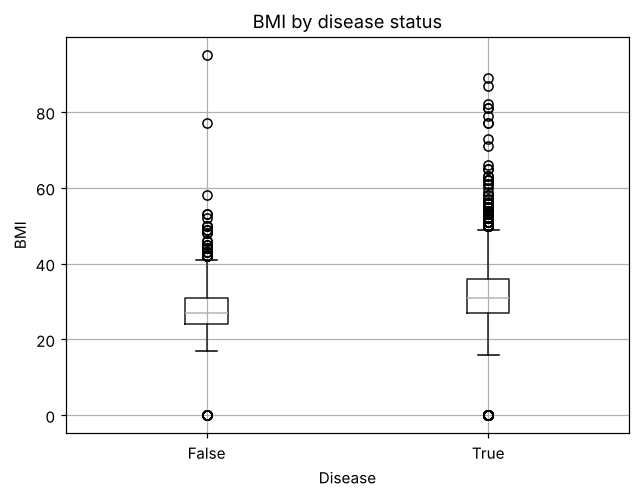

In [11]:
df.boxplot(column="bmi", by="dissease")
plt.title("BMI by disease status")
plt.suptitle("")
plt.xlabel("Disease")
plt.ylabel("BMI")
plt.show()

In [12]:
# percentage of each category within the healthy and the diseased group
rows = []
for col in categorical_cols:
    tab = pd.crosstab(df[col], df["dissease"], normalize="columns") * 100
    for level in tab.index:
        rows.append({"feature": col, "category": level,
                     "healthy_%": round(tab.loc[level, False], 1),
                     "diseased_%": round(tab.loc[level, True], 1)})
pd.DataFrame(rows)

,feature,category,healthy_%,diseased_%
0,gender,female,40.0,35.0
1,gender,male,60.0,65.0
2,amount_activity,active,75.8,64.8
3,amount_activity,notactive,24.2,35.2
4,high_chol,high,42.0,64.0
5,high_chol,normal,58.0,36.0
6,chol_check,checked,96.2,99.4
7,chol_check,notchecked,3.8,0.6
8,history_stroke,False,95.6,90.7
9,history_stroke,True,4.4,9.3


Patients with the disease are on average older, have a higher BMI and rate their general health
worse. They also more often have high blood pressure (87% vs 62%), high cholesterol (64% vs 42%),
difficulty walking (36% vs 13%) and a history of heart disease (24% vs 11%).

### 2.6 Correlation between numeric features

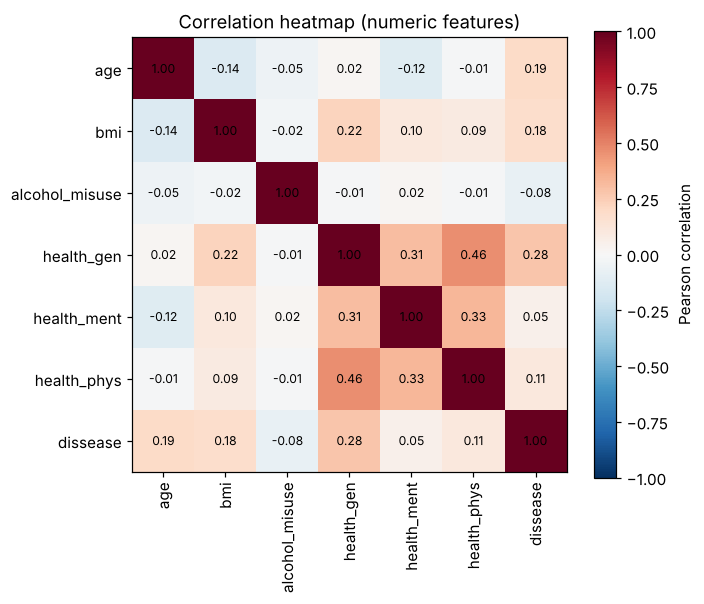

In [13]:
corr = df[numeric_cols + ["dissease"]].corr()

plt.figure(figsize=(6.5, 5.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation heatmap (numeric features)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", dpi=150)
plt.show()

None of the numeric features are strongly correlated with each other (the highest is general
health with physical health days, 0.46), so I kept all of them. General health has the strongest
correlation with the disease label (0.28).

## 3. Train / test split and missing data

I hold out 20% of the patients as a test set, stratified so that both sets keep the same
83 / 17 class ratio. The test set is only used once, at the end.

**Missing data.** Numeric features are filled with the median and categorical features with the
most frequent category. The imputation sits inside a scikit-learn `Pipeline`, so the median and
the most frequent category are learned from the training data only (and, during cross-validation,
from the training folds only). That way no information from the test data leaks into the model.

Numeric features are then standardised and categorical features one-hot encoded.

In [14]:
X = df.drop(columns=["dissease"])
y = df["dissease"].map({True: 1, False: 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train shape:", X_train.shape)
print("Test shape: ", X_test.shape)

Train shape: (4103, 17)
Test shape:  (1026, 17)


In [15]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

## 4. Unsupervised analysis

Before training a classifier I looked at whether the patients form natural groups without using
the disease label: PCA to see the main directions of variation, then k-means to look for
sub-groups. This uses the training data only.

Variance explained by the first 5 PCs: [0.201 0.12  0.103 0.093 0.071]
Cumulative: [0.201 0.321 0.424 0.516 0.587]


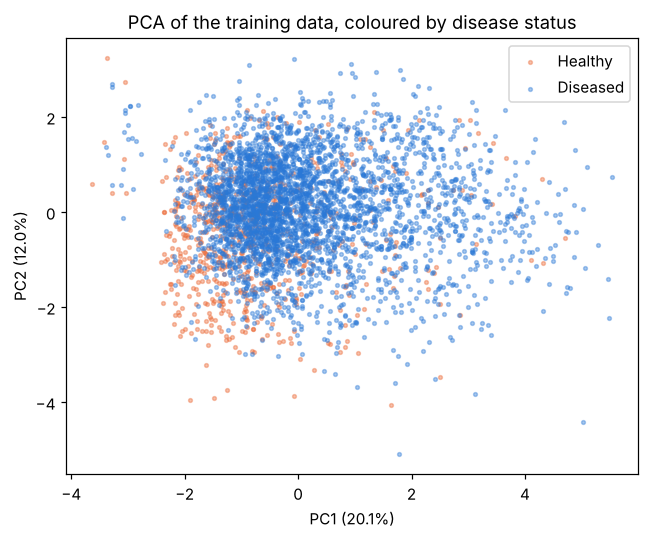

In [16]:
X_train_prep = preprocessor.fit_transform(X_train)
X_train_prep = X_train_prep.toarray() if hasattr(X_train_prep, "toarray") else X_train_prep

pca = PCA(n_components=10, random_state=42)
pcs = pca.fit_transform(X_train_prep)
print("Variance explained by the first 5 PCs:", pca.explained_variance_ratio_[:5].round(3))
print("Cumulative:", pca.explained_variance_ratio_[:5].cumsum().round(3))

fig, ax = plt.subplots(figsize=(6, 5))
for label, name, colour in [(0, "Healthy", "#eb6834"), (1, "Diseased", "#2a78d6")]:
    mask = (y_train == label).values
    ax.scatter(pcs[mask, 0], pcs[mask, 1], s=6, alpha=0.4, color=colour, label=name)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("PCA of the training data, coloured by disease status")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/pca_disease_status.png", dpi=150)
plt.show()

In [17]:
# how many sub-groups? compare silhouette scores for k = 2 to 6
sil = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_train_prep)
    sil[k] = silhouette_score(X_train_prep, labels)
pd.Series(sil, name="silhouette").round(3)

2    0.215
3    0.225
4    0.096
5    0.105
6    0.101
Name: silhouette, dtype: float64

In [18]:
best_k = max(sil, key=sil.get)
km = KMeans(n_clusters=best_k, n_init=10, random_state=42)
clusters = km.fit_predict(X_train_prep)

profile = X_train.copy()
profile["cluster"] = clusters
profile["diseased"] = y_train.values

summary = profile.groupby("cluster")[numeric_cols + ["diseased"]].mean().round(2)
summary.insert(0, "n_patients", profile["cluster"].value_counts().sort_index())
summary

,n_patients,age,bmi,alcohol_misuse,health_gen,health_ment,health_phys,diseased
cluster,,,,,,,,
0,89,56.08,29.33,17.73,2.92,4.36,6.95,0.61
1,963,60.95,33.85,1.98,4.18,12.67,22.55,0.91
2,3051,62.87,30.39,1.96,2.77,1.00,1.68,0.81


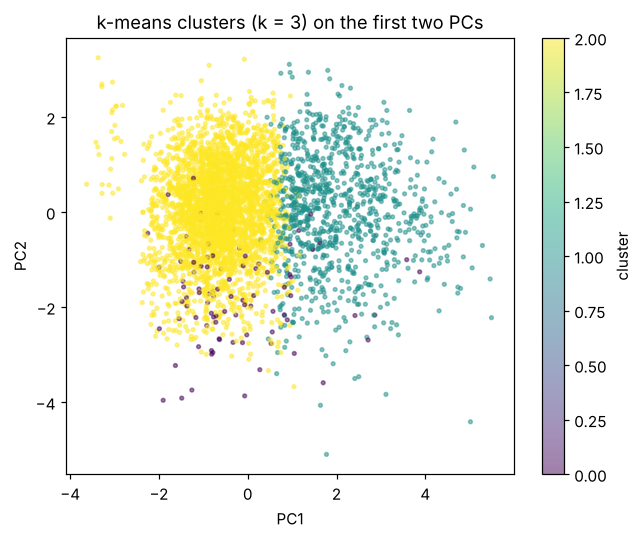

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=clusters, s=6, alpha=0.5, cmap="viridis")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"k-means clusters (k = {best_k}) on the first two PCs")
plt.colorbar(sc, label="cluster")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/kmeans_clusters.png", dpi=150)
plt.show()

The first two principal components explain only about a third of the variance, and healthy and
diseased patients overlap heavily in the PCA plot, so the classes are not cleanly separable.

The silhouette scores are low for every k, so the patients do not fall into sharply separated
sub-groups. The best solution (k = 3) is still informative:

- a large group in fairly good health (about 3,050 patients, 81% diseased)
- a group in **poor health**, with many days of poor physical and mental health and a worse general
  health rating (about 960 patients, **91% diseased**)
- a small group of **heavy drinkers**, around 18 drinks per week (89 patients, 61% diseased)

So the sub-groups follow health status and alcohol use, and the disease is more common in the
poor-health group, but no cluster corresponds to "healthy" or "diseased".

## 5. Supervised models

Five classifiers are compared with 5-fold stratified cross-validation on the training set.
Each one is wrapped in the same preprocessing pipeline.

In [20]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "SVM": SVC(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

results = []
for name, model in models.items():
    clf = Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
    cv_results = cross_validate(clf, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        "Model": name,
        "Accuracy": cv_results["test_accuracy"].mean(),
        "Precision": cv_results["test_precision"].mean(),
        "Recall": cv_results["test_recall"].mean(),
        "F1": cv_results["test_f1"].mean(),
        "ROC_AUC": cv_results["test_roc_auc"].mean()
    })

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,SVM,0.859,0.863,0.987,0.921,0.729
1,Random Forest,0.856,0.869,0.973,0.918,0.748
2,KNN,0.853,0.861,0.982,0.917,0.729
3,Logistic Regression,0.851,0.865,0.972,0.915,0.781
4,Decision Tree,0.751,0.860,0.836,0.848,0.589


In [21]:
# which model wins depends on the metric
for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]:
    print(f"Best by {metric:<9}: {results_df.sort_values(metric, ascending=False).iloc[0]['Model']}")

best_model_name = results_df.iloc[0]["Model"]     # chosen by F1
print("\nSelected model:", best_model_name)

Best by Accuracy : SVM
Best by Precision: Random Forest
Best by Recall   : SVM
Best by F1       : SVM
Best by ROC_AUC  : Logistic Regression

Selected model: SVM


Apart from the decision tree, the models are close together on accuracy and F1. The SVM is best on
accuracy, recall and F1, the random forest on precision, and logistic regression clearly on ROC-AUC
(0.78 against 0.73 for the SVM). I selected the model with the best F1 score, the
**SVM (RBF kernel)**, because F1 balances precision and recall for the diseased class. With hindsight
the ROC-AUC difference matters, and I come back to it in the summary.

## 6. Final model and evaluation on the test set

In [22]:
final_model = Pipeline(steps=[("preprocess", preprocessor), ("model", clone(models[best_model_name]))])
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)
y_score = final_model.decision_function(X_test)     # SVM score, used for the ROC curve

print(classification_report(y_test, y_pred, target_names=["Healthy", "Diseased"]))
print("Test ROC-AUC:        ", round(roc_auc_score(y_test, y_score), 3))
print("Balanced accuracy:   ", round(balanced_accuracy_score(y_test, y_pred), 3))
print("Majority-class baseline accuracy:", round(y_test.mean(), 3))

              precision    recall  f1-score   support

     Healthy       0.70      0.22      0.33       176
    Diseased       0.86      0.98      0.92       850

    accuracy                           0.85      1026
   macro avg       0.78      0.60      0.62      1026
weighted avg       0.83      0.85      0.82      1026

Test ROC-AUC:         0.723
Balanced accuracy:    0.599
Majority-class baseline accuracy: 0.828


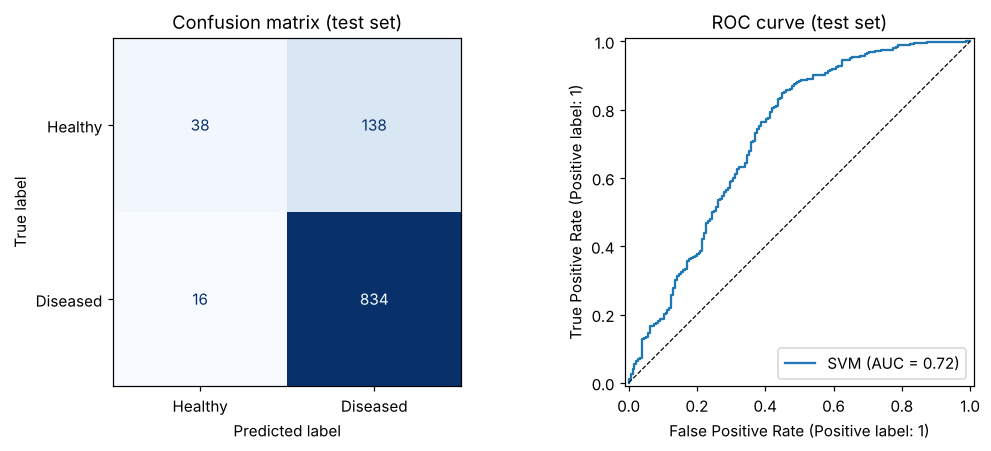

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Healthy", "Diseased"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, y_score, name="SVM", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrix_roc.png", dpi=150)
plt.show()

The SVM finds almost all diseased patients (recall 0.98) but only about a fifth of the healthy
ones. Its accuracy of 85% is only slightly above the 83% that comes from predicting "diseased" for
everyone, and the balanced accuracy is about 0.60. So the headline accuracy looks better than the
model really is; the ROC-AUC of about 0.72 is the fairer summary.

### Is the model overfitting?

In [24]:
print("Training accuracy:", round(final_model.score(X_train, y_train), 3))
print("Test accuracy:    ", round(final_model.score(X_test, y_test), 3))

cv_scores = cross_val_score(final_model, X_train, y_train, cv=cv, scoring="roc_auc")
print("\nCV ROC-AUC per fold:", cv_scores.round(3))
print("Mean CV ROC-AUC:    ", round(cv_scores.mean(), 3), "+/-", round(cv_scores.std(), 3))

Training accuracy: 0.866
Test accuracy:     0.85



CV ROC-AUC per fold: [0.713 0.76  0.744 0.716 0.713]
Mean CV ROC-AUC:     0.729 +/- 0.019


Training and test accuracy are close (0.87 vs 0.85) and the ROC-AUC is similar across the five
folds and on the test set, so there is no sign of serious overfitting. The model generalises;
its limit is how well the two classes can be separated at all.

## 7. Feature importance and removing the best feature

An RBF SVM has no coefficients to read, so I used permutation importance: shuffle one feature at a
time in the test set and measure how much the ROC-AUC drops.

In [25]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=42)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

importance_df.head(10).round(4)

,feature,importance_mean,importance_std
0,health_gen,0.0998,0.0130
1,age,0.0521,0.0060
2,bmi,0.0509,0.0145
3,walking_diff,0.0247,0.0069
4,high_bp,0.0130,0.0106
5,high_chol,0.0111,0.0041
6,alcohol_misuse,0.0021,0.0039
7,history_stroke,0.0020,0.0042
8,chol_check,-0.0004,0.0031
9,fruits,-0.0011,0.0044


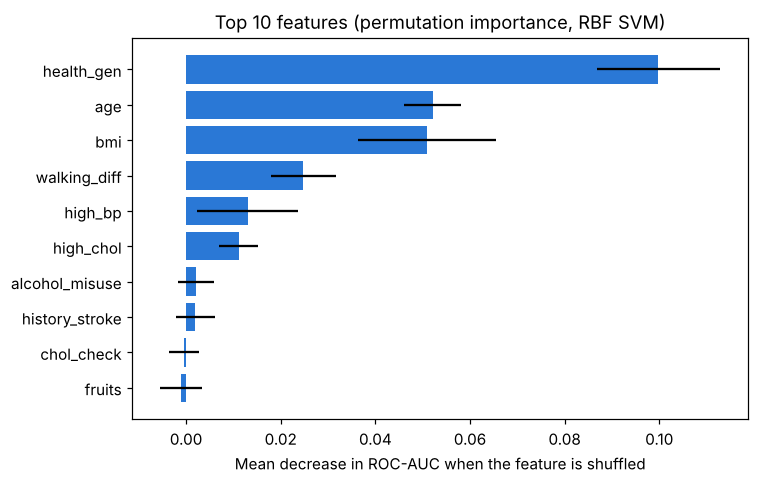

Most important feature: health_gen


In [26]:
top = importance_df.head(10).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#2a78d6")
plt.xlabel("Mean decrease in ROC-AUC when the feature is shuffled")
plt.title("Top 10 features (permutation importance, RBF SVM)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/feature_importance.png", dpi=150)
plt.show()

best_feature = importance_df.iloc[0]["feature"]
print("Most important feature:", best_feature)

### Importance by feature group

In [27]:
feature_groups = {
    "Lifestyle": ["history_smoking", "alcohol_misuse", "amount_activity", "fruits", "vegetables"],
    "Medical history": ["high_bp", "high_chol", "chol_check", "history_stroke", "history_heart_disease"],
    "Health status / function": ["health_gen", "health_ment", "health_phys", "walking_diff"],
    "Demographics": ["age", "gender", "bmi"],
}

def group_of_feature(f):
    for g, cols in feature_groups.items():
        if f in cols:
            return g
    return "Other"

importance_df["group"] = importance_df["feature"].apply(group_of_feature)
importance_df.groupby("group")["importance_mean"].sum().sort_values(ascending=False).round(4)

group
Health status / function    0.1155
Demographics                0.0972
Medical history             0.0213
Lifestyle                  -0.0075
Name: importance_mean, dtype: float64

### Is the ranking stable? Permutation importance in each cross-validation fold

In [28]:
fold_imps = []
for fold_id, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_val, y_val = X_train.iloc[val_idx], y_train.iloc[val_idx]

    model_fold = clone(final_model)
    model_fold.fit(X_tr, y_tr)

    perm_fold = permutation_importance(model_fold, X_val, y_val, scoring="roc_auc",
                                       n_repeats=5, random_state=42)
    fold_imps.append(pd.Series(perm_fold.importances_mean, index=X_val.columns, name=f"fold{fold_id}"))

imp_folds_df = pd.concat(fold_imps, axis=1)
imp_stability = pd.DataFrame({
    "mean_importance": imp_folds_df.mean(axis=1),
    "std_importance": imp_folds_df.std(axis=1),
}).sort_values("mean_importance", ascending=False)

imp_stability.head(10).round(4)

,mean_importance,std_importance
health_gen,0.0782,0.0108
age,0.0446,0.0103
bmi,0.0269,0.0091
walking_diff,0.0180,0.0044
high_chol,0.0105,0.0042
vegetables,0.0062,0.0052
chol_check,0.0055,0.0032
health_phys,0.0040,0.0088
alcohol_misuse,0.0039,0.0098
high_bp,0.0026,0.0079


General health (`health_gen`) is the most important feature, followed by age and BMI. The same
three come out on top in every cross-validation fold, so the ranking is stable. Grouped together,
health status and demographics carry almost all of the signal; lifestyle features (smoking, alcohol,
activity, fruit, vegetables) add close to nothing for this model.

### What happens without the best feature?

In [29]:
X_train_red = X_train.drop(columns=best_feature)
X_test_red = X_test.drop(columns=best_feature)

numeric_cols_red = [c for c in numeric_cols if c != best_feature]
categorical_cols_red = [c for c in categorical_cols if c != best_feature]

preprocessor_red = ColumnTransformer(transformers=[
    ("num", clone(numeric_transformer), numeric_cols_red),
    ("cat", clone(categorical_transformer), categorical_cols_red)
])

final_model_red = Pipeline(steps=[
    ("preprocess", preprocessor_red),
    ("model", SVC(random_state=42))
])
final_model_red.fit(X_train_red, y_train)

roc_auc_original = roc_auc_score(y_test, final_model.decision_function(X_test))
roc_auc_reduced = roc_auc_score(y_test, final_model_red.decision_function(X_test_red))

print("ROC-AUC with all features:      ", round(roc_auc_original, 3))
print(f"ROC-AUC without {best_feature}:    ", round(roc_auc_reduced, 3))
print("Drop:                           ", round(roc_auc_original - roc_auc_reduced, 3))

ROC-AUC with all features:       0.723
ROC-AUC without health_gen:     0.698
Drop:                            0.025


In [30]:
def get_metrics(model, X, y):
    pred = model.predict(X)
    return {"Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC_AUC": roc_auc_score(y, model.decision_function(X))}

comparison_df = pd.DataFrame([get_metrics(final_model, X_test, y_test),
                              get_metrics(final_model_red, X_test_red, y_test)],
                             index=["All features", f"Without {best_feature}"])
comparison_df.round(3)

,Accuracy,Precision,Recall,F1,ROC_AUC
All features,0.850,0.858,0.981,0.915,0.723
Without health_gen,0.848,0.854,0.985,0.915,0.698


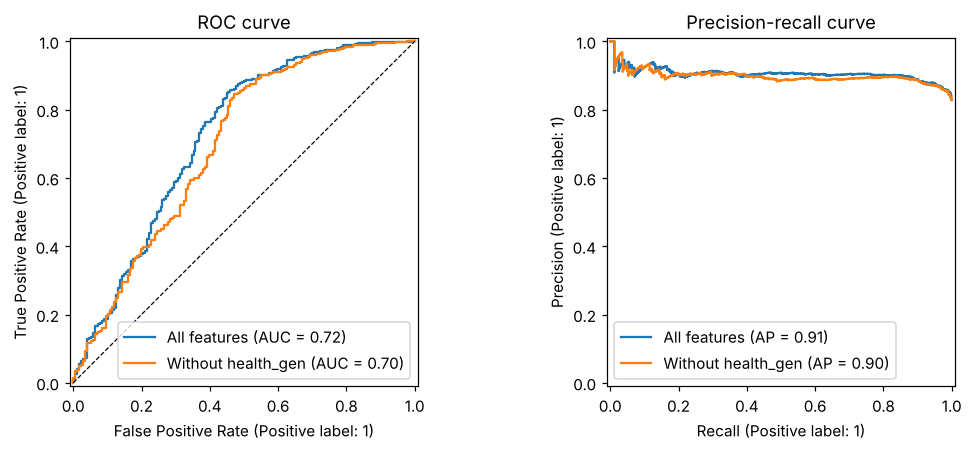

Share of test patients given the same prediction by both models: 0.986


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
RocCurveDisplay.from_estimator(final_model, X_test, y_test, name="All features", ax=axes[0])
RocCurveDisplay.from_estimator(final_model_red, X_test_red, y_test, name=f"Without {best_feature}", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_title("ROC curve")

PrecisionRecallDisplay.from_estimator(final_model, X_test, y_test, name="All features", ax=axes[1])
PrecisionRecallDisplay.from_estimator(final_model_red, X_test_red, y_test, name=f"Without {best_feature}", ax=axes[1])
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/with_without_best_feature.png", dpi=150)
plt.show()

agreement = (final_model.predict(X_test) == final_model_red.predict(X_test_red)).mean()
print("Share of test patients given the same prediction by both models:", round(agreement, 3))

Removing general health lowers the ROC-AUC, so the model does lose ranking ability. Accuracy,
precision, recall and F1 barely move, and the two models give the same prediction for almost every
patient. The reason is the class imbalance: both models predict "diseased" for nearly everyone, so
threshold-based metrics hide the loss that ROC-AUC shows.

## 8. Threshold and error analysis

The SVM classifies a patient as diseased when its decision score is above 0. Here I check how
precision, recall and F1 change if that cut-off is moved, and which patients the model gets wrong.

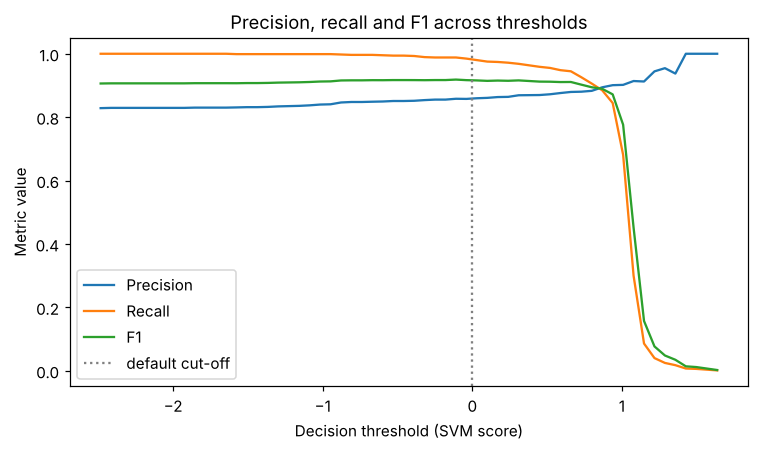

threshold   -0.110
accuracy     0.855
precision    0.858
recall       0.988
f1           0.919
Name: 34, dtype: float64

In [32]:
scores = final_model.decision_function(X_test)
thresholds = np.linspace(scores.min(), scores.max(), 60)

rows = []
for t in thresholds:
    y_pred_t = (scores >= t).astype(int)
    rows.append({"threshold": t,
                 "accuracy": accuracy_score(y_test, y_pred_t),
                 "precision": precision_score(y_test, y_pred_t, zero_division=0),
                 "recall": recall_score(y_test, y_pred_t, zero_division=0),
                 "f1": f1_score(y_test, y_pred_t, zero_division=0)})
thr_df = pd.DataFrame(rows)

plt.figure(figsize=(7, 4.2))
plt.plot(thr_df["threshold"], thr_df["precision"], label="Precision")
plt.plot(thr_df["threshold"], thr_df["recall"], label="Recall")
plt.plot(thr_df["threshold"], thr_df["f1"], label="F1")
plt.axvline(0, color="grey", linestyle=":", label="default cut-off")
plt.xlabel("Decision threshold (SVM score)")
plt.ylabel("Metric value")
plt.title("Precision, recall and F1 across thresholds")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/threshold_sweep.png", dpi=150)
plt.show()

best_row = thr_df.loc[thr_df["f1"].idxmax()]
best_threshold = best_row["threshold"]
best_row.round(3)

Note: this threshold is picked on the test set only to see how sensitive the result is. The F1 score
hardly changes around the default cut-off, so there is little to gain. For a real model the
threshold would have to be chosen on validation data, not on the test set.

In [33]:
audit = X_test.copy()
audit["y_true"] = y_test.values
audit["svm_score"] = scores
audit["y_pred"] = (scores >= best_threshold).astype(int)

audit["error_type"] = "Correct"
audit.loc[(audit.y_true == 1) & (audit.y_pred == 0), "error_type"] = "False Negative"
audit.loc[(audit.y_true == 0) & (audit.y_pred == 1), "error_type"] = "False Positive"

print(audit["error_type"].value_counts())
audit.groupby("error_type")[numeric_cols].mean().round(2)

error_type
Correct           877
False Positive    139
False Negative     10
Name: count, dtype: int64


,age,bmi,alcohol_misuse,health_gen,health_ment,health_phys
error_type,,,,,,
Correct,62.50,31.69,2.22,3.19,4.53,7.73
False Negative,37.30,25.40,3.50,2.20,2.20,0.80
False Positive,62.13,29.70,3.21,2.58,2.81,3.10


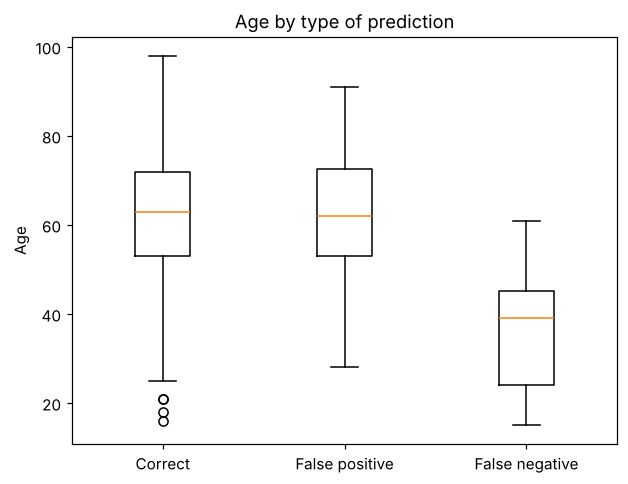

In [34]:
data = [audit.loc[audit["error_type"] == e, "age"].dropna()
        for e in ["Correct", "False Positive", "False Negative"]]
plt.boxplot(data, tick_labels=["Correct", "False positive", "False negative"])
plt.title("Age by type of prediction")
plt.ylabel("Age")
plt.show()

Most errors are **false positives**: healthy people classified as diseased. They look much like the
diseased patients in age, and differ only moderately in BMI and general health, which is why the
model cannot tell them apart. The few false negatives are younger patients with a low BMI and good
self-rated health, in other words diseased patients who look healthy on these features.

## 9. Summary

- The dataset has 5,129 patients, 83% of them with the disease. Three features have 18 to 30%
  missing values; I imputed with the median / most frequent value inside the pipeline.
- PCA and k-means show no clearly separated patient sub-groups, and the two classes overlap.
- Five classifiers perform similarly. The RBF SVM had the best cross-validated F1.
- On the held-out test set the SVM reaches about 85% accuracy and a ROC-AUC of about 0.72. It finds
  98% of diseased patients but only about 22% of healthy ones.
- The model is not overfitting; training, cross-validation and test results agree.
- General health is the most important feature, then age and BMI. Without it the ROC-AUC falls,
  while accuracy and F1 stay almost the same.

**Limitations and what I would do next**

- Because of the class imbalance, accuracy and F1 for the diseased class flatter the model. Choosing
  by F1 picked the SVM, but logistic regression had a clearly higher cross-validated ROC-AUC
  (0.78 vs 0.73). I would now choose the model on ROC-AUC or balanced accuracy, and try class
  weighting or resampling so that healthy patients are recognised better.
- The implausible values (BMI of 0, more than 30 "days in the past 30 days") should be treated as
  missing rather than left in.
- The SVM was used with default settings; hyperparameters (C, gamma) were not tuned.
- Simple imputation ignores that 30% of smoking history is missing; a missing-indicator feature or
  model-based imputation could do better.